<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/15_Smart_Grid_Power_System_Attacks/QNN_FDIQuantumData_Nader2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum learning on noisy Fourier waveforms for smart-grid false-data injection: Nader et al. (2023) step by step

This notebook rebuilds the experiment of one paper:

Andrew Nader, Marc-Andre Dubois and Deepa Kundur, "Exploring quantum learning in the smart grid through the evolution of noisy finite Fourier series", *Frontiers in Energy Research* 11:1061602, 2023. DOI [10.3389/fenrg.2023.1061602](https://doi.org/10.3389/fenrg.2023.1061602).

**What the notebook does.** The paper does not use a recorded grid dataset. It invents the data. A noisy 60 Hz-like waveform from a real-time measurement device is sampled, and each sample is labelled "normal" or "false data injection (FDI)" by a rule built from a *quantum kernel* (Huang et al., 2021). A differential-evolution search then looks for the waveform that makes this labelling as hard as possible for a classical learner. Finally a classical neural network (inputs: the sample `(x, y)`) is compared with the same network fed with *quantum features* (one-qubit reduced density matrices of a simulated 4-qubit circuit). Everything is generated inside the notebook, so no download and no Hugging Face token are needed.

**How to run it.** Open in Google Colab, keep the normal CPU runtime, choose Runtime, then Run all. `FAST_MODE = True` finishes in about 7 minutes; `FAST_MODE = False` (the setting saved in this file, about one hour) uses the larger budgets listed in Section 3.

**What you get at the end.** The evolved waveforms (the paper's Figures 4 to 6), the 10-fold cross-validation tables (the paper's Tables 2 to 4) for the classical and the quantum-feature network, the drawn quantum circuit, and a side-by-side check of every number the paper reports.

**An honest warning before you start.** The "quantum advantage" in this paper holds *by construction*: the labels are defined from the same quantum feature map that the quantum model receives. The notebook reproduces that construction faithfully and then discusses in Section 11 what this does and does not prove for real smart grids.

## 1. The paper in one page

**Problem.** Smart-grid devices (real-time measurement devices, RTMD) report noisy periodic voltage/current waveforms. In a false-data-injection (FDI) attack the attacker makes the RTMD emit anomalous samples that are hard to tell from ordinary noise. The paper imagines a future grid with quantum sensors/devices, so that the data the learner sees is *quantum data*, and asks how big the gap between a quantum and a classical learner can become.

**Decision.** Binary classification of each sampled point `(x_k, y_k)` into normal (0) or FDI (1).

**Data (synthetic).**
1. A waveform is a random finite Fourier series on `[-L/2, L/2]` with `L = 20` (Filip et al., 2019): `f(x) = a0 + sqrt(2) * sum_j [a_j cos(2 pi j x / L) + b_j sin(2 pi j x / L)]` plus a per-point perturbation `eps_i`. The wavelength parameter `lambda` sets `m = floor(L / lambda)` harmonics.
2. Points `X_i = (x_i, f(x_i))` are 1000 equally spaced samples.
3. Labels come from the "quantum algorithmic primitive" of Huang et al. (2021): with a classical RBF kernel Gram matrix `G_C` and a *projected quantum kernel* Gram matrix `G_Q`, the label vector with maximal quantum advantage is `l = sqrt(G_Q) v`, where `v` is the top eigenvector of `sqrt(G_Q) G_C^-1 sqrt(G_Q)`. Binary labels are `l > median(l)`, and 5% of them are flipped at random.
4. The quantum feature map is the 1-reduced density matrix on every qubit of `V(x / n_trotter)^n_trotter U_1qb |0>`, with a Hamiltonian-evolution `V` (Heisenberg couplings XX+YY+ZZ) and `n_trotter = 10`.
5. The *geometric difference* `g = sqrt(|| sqrt(G_Q) G_C^-1 sqrt(G_Q) ||_inf)` measures the potential quantum advantage. A differential-evolution (DE) search over `theta = [a, b, eps]` maximises `g` (population 50, 6 hours on Colab per `lambda`).

**Models.** Classical network: fully connected `(128, 64, 32, 16)` ReLU neurons and one sigmoid neuron on `(x, y)`. Quantum model: the same architecture on the quantum features. Both trained with binary cross-entropy, Adam, 500 epochs, inputs standardised, 10-fold cross-validation.

**Claims to check (Tables 2 to 4).**

| lambda | Classical acc. | Quantum acc. |
|---|---|---|
| 5 | 0.833 | 0.910 |
| 2.5 | 0.707 | 0.903 |
| 1 | 0.666 | 0.914 |

The gap grows from about 7 points (lambda = 5) to more than 25 points (lambda = 1) because the classical score falls while the quantum score stays near 0.91.

### What follows the paper and what had to be chosen

The paper does not give code and omits several details. Everything below that is not in the "Paper" column is a choice of this notebook and is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Waveform family, `L`, `lambda in {5, 2.5, 1}` | Eq. 3 and 4, `L = 20` | Same |
| Number of points | 1000 | 1000 in the paper and in the full run; **500** in fast mode |
| DE population / budget | 50, 6 h per `lambda` on Colab | Population 50 and 40 generations (full, about 2000 fitness calls per wavelength), 20 and 15 (fast). The paper does not state its number of generations (6 h), so the evolved `g` may be smaller than the paper's |
| DE operator | `theta' = theta1 + (theta2 - theta3)/2`, scipy `differential_evolution` | scipy `differential_evolution`, `rand1bin`, mutation 0.5, recombination 0.7, own initial population of 50 |
| Initial `a_j, b_j` | `N(0, 1/(2m+1))`, bounds `+-4/(2m+1)` | standard deviation `1/(2m+1)` (matches the bounds) |
| `eps` | `N(0, 0.01)`, bounds `+-0.04` | standard deviation 0.01, bounds `+-0.04`, added to `f(x_i)` (Eq. 4 puts it inside the sum, which looks like a typo) |
| Number of qubits | not stated | **4** qubits, open chain of 3 Heisenberg bonds |
| How the 2 inputs `(x, y)` reach the qubits | `V(x) = exp(-i sum_k x_k (XX+YY+ZZ)_k,k+1)`, input is 2-dimensional | bond `k` uses coefficient `x` for even `k` and `y` for odd `k` |
| Random single-qubit rotations `U_1qb` | "a wall of random rotations" | one fixed U3(theta, phi, lambda) per qubit drawn with `SEED` |
| Kernel widths | not stated | `gamma_C = gamma_Q = 1` |
| Regularisation of `G_C^-1` | not stated | `G_C + 1e-3 I` |
| Simulator | not stated | exact statevector (numpy), checked against Qiskit |
| Network | Keras, (128,64,32,16)+sigmoid, BCE, Adam, 500 epochs | scikit-learn `MLPClassifier` with the same layers, Adam, log-loss, 500 epochs (150 in fast mode), mini-batch 200 (not stated in the paper) |
| Cross-validation | 10 fold | 10 fold, stratified; scaler fitted on the training folds only |
| Classical baselines beyond the NN | none | Random forest and RBF-SVM on the same inputs |

## 2. Install the libraries

Colab already has NumPy, SciPy, pandas, scikit-learn and Matplotlib. Qiskit is used only to draw and cross-check the circuit (circuit section further down). The cell installs it only when it is missing or when running in Colab. If Colab asks for a restart, accept and run again from the next cell.

In [1]:
import importlib.util, subprocess, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit") is None or importlib.util.find_spec("pylatexenc") is None:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "pylatexenc"], check=False)

## 3. Settings

All tunable numbers are in this one cell.

* `FAST_MODE = True` gives a class demo (a few minutes). `FAST_MODE = False` uses the larger budgets.
* `N_POINTS`, `POP`, `MAXITER` are the dataset size and the DE budget (paper: 1000 points, population 50, 6 hours).
* `EPOCHS` is the number of training epochs of the neural networks (paper: 500).
* `N_QUBITS`, `N_TROTTER` define the quantum feature map (`n_trotter = 10` is the paper's value; four qubits are our choice).

In [2]:
FAST_MODE = False           # True: class demo (about 7 min); False: larger budgets (about one hour on a laptop CPU)

SEED = 42
L = 20.0                    # period of the waveform, paper Table 1
LAMBDAS = [5.0, 2.5, 1.0]   # the three wavelengths of the paper's experiments
N_QUBITS = 4                # CHOICE: the paper does not state the qubit count
N_TROTTER = 10              # paper: n_trotter = 10
GAMMA_C = 1.0               # CHOICE: width of the classical RBF kernel
GAMMA_Q = 1.0               # CHOICE: width of the projected quantum kernel
GEO_REG = 1e-3              # CHOICE: ridge added to G_C before inverting
LABEL_NOISE = 0.05          # paper: 5% of the labels flipped
N_FOLDS = 10                # paper: 10-fold cross-validation
HIDDEN = (128, 64, 32, 16)  # paper: hidden ReLU layers
EPS_STD, EPS_BOUND = 0.01, 0.04   # paper Table 1

if FAST_MODE:
    N_POINTS, POP, MAXITER, EPOCHS = 500, 20, 15, 150
else:
    N_POINTS, POP, MAXITER, EPOCHS = 1000, 50, 40, 500    # paper: 1000 points, population 50, ~6 h per lambda (here 40 generations, 2000 fitness calls)

IBM_TOKEN = ""              # not needed: everything is simulated locally
PAPER = {  # (accuracy, precision, recall, F1) means from Tables 2 to 4
    5.0: {"Classical": (0.833, 0.868, 0.796, 0.829), "Quantum": (0.910, 0.914, 0.912, 0.912)},
    2.5: {"Classical": (0.707, 0.734, 0.655, 0.688), "Quantum": (0.903, 0.901, 0.911, 0.905)},
    1.0: {"Classical": (0.666, 0.656, 0.690, 0.670), "Quantum": (0.914, 0.904, 0.927, 0.915)},
}

### Imports and seeds

In [3]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import qiskit
from scipy.optimize import differential_evolution
from scipy.linalg import cholesky, solve_triangular
from scipy.sparse.linalg import LinearOperator, eigsh
from scipy.spatial.distance import cdist
from scipy.stats import median_abs_deviation
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
rng_global = np.random.default_rng(SEED)
print("numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| qiskit", qiskit.__version__)
print(f"FAST_MODE={FAST_MODE}  N_POINTS={N_POINTS}  POP={POP}  MAXITER={MAXITER}  EPOCHS={EPOCHS}")

numpy 2.5.4 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | qiskit 2.5.2
FAST_MODE=False  N_POINTS=1000  POP=50  MAXITER=40  EPOCHS=500


## 4. The quantum feature map

For a data point `X = (x, y)` the paper builds the state `V(X / n_trotter)^n_trotter U_1qb |0>` and keeps the **1-reduced density matrix of every qubit**. A single-qubit density matrix is fully described by its Bloch vector `(<X>, <Y>, <Z>)`, so four qubits give **12 real quantum features** per point.

* `U_1qb` is a "wall" of random single-qubit rotations: one fixed U3 gate per qubit with angles drawn once from the seed.
* One Trotter step applies, for each neighbouring pair `(k, k+1)`, the Heisenberg exchange `exp(-i t (X X + Y Y + Z Z))` with `t = coefficient / n_trotter`. This gate has a closed form: the two-qubit state splits into the triplet (eigenvalue +1, phase `e^{-it}`) and the singlet (eigenvalue -3, phase `e^{3it}`), and the singlet projector is `(I - SWAP)/2`. We use that to simulate thousands of points at once with plain NumPy. the circuit section further down draws the same circuit in Qiskit and asserts that both agree to numerical precision.
* The **projected quantum kernel** is `k_Q(X, X') = exp(-gamma_Q * sum_k || rho_k(X) - rho_k(X') ||_F^2)`. For Bloch vectors, `|| rho - rho' ||_F^2 = |r - r'|^2 / 2`.
* The classical kernel is the RBF kernel on the raw `(x, y)`.

In [4]:
# CHOICE: fixed random single-qubit rotation wall U_1qb (one U3 per qubit), drawn once from SEED
ANGLES = np.random.default_rng(SEED).uniform(0, 2 * np.pi, (N_QUBITS, 3))

def u3_matrix(theta, phi, lam):
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    return np.array([[c, -np.exp(1j * lam) * s], [np.exp(1j * phi) * s, np.exp(1j * (phi + lam)) * c]])

def initial_state():
    psi = np.zeros((2,) * N_QUBITS, dtype=complex)
    psi[(0,) * N_QUBITS] = 1.0
    for q in range(N_QUBITS):
        psi = np.moveaxis(np.tensordot(u3_matrix(*ANGLES[q]), psi, axes=([1], [q])), 0, q)
    return psi
PSI0 = initial_state()

def quantum_features(X):
    """12 Bloch-vector features (<X>,<Y>,<Z> of every qubit) of V(X/n)^n U_1qb |0>, for a batch X of shape (B, 2)."""
    B = len(X)
    psi = np.broadcast_to(PSI0, (B,) + PSI0.shape).astype(complex).copy()
    shape = (B,) + (1,) * N_QUBITS
    for _ in range(N_TROTTER):
        for k in range(N_QUBITS - 1):
            t = X[:, k % 2] / N_TROTTER          # CHOICE: bond k uses x (k even) or y (k odd)
            swapped = np.swapaxes(psi, k + 1, k + 2)
            singlet = (psi - swapped) / 2          # projector (I - SWAP)/2 applied to psi
            psi = np.exp(-1j * t).reshape(shape) * psi + (np.exp(3j * t) - np.exp(-1j * t)).reshape(shape) * singlet
    feats = []
    for q in range(N_QUBITS):
        M = np.moveaxis(psi, q + 1, 1).reshape(B, 2, -1)
        r01 = np.einsum("bi,bi->b", M[:, 0], M[:, 1].conj())
        z = (np.abs(M[:, 0]) ** 2).sum(1) - (np.abs(M[:, 1]) ** 2).sum(1)
        feats += [2 * r01.real, -2 * r01.imag, z]
    return np.stack(feats, 1)

FEATURE_NAMES = [f"q{q}_{p}" for q in range(N_QUBITS) for p in "XYZ"]

def gram_quantum(F):   # projected quantum kernel, ||rho-rho'||_F^2 = |r-r'|^2 / 2
    return np.exp(-GAMMA_Q * 0.5 * cdist(F, F, "sqeuclidean"))

def gram_classical(X): # RBF kernel on the raw (x, y)
    return np.exp(-GAMMA_C * cdist(X, X, "sqeuclidean"))

def sqrtm_psd(G):
    w, V = np.linalg.eigh(G)
    return (V * np.sqrt(np.clip(w, 0, None))) @ V.T

def geometric_matrix(GC, GQ):
    S = sqrtm_psd(GQ)
    M = S @ np.linalg.solve(GC + GEO_REG * np.eye(len(GC)), S)
    return S, (M + M.T) / 2

def geometric_difference(GC, GQ):
    """Exact g = sqrt(|| sqrt(G_Q) (G_C+reg I)^-1 sqrt(G_Q) ||), paper Eq. 6, via a full eigendecomposition."""
    _, M = geometric_matrix(GC, GQ)
    return float(np.sqrt(np.linalg.eigvalsh(M)[-1]))

def geometric_difference_fast(GC, GQ):
    """Same number, much cheaper (used inside the DE loop). The eigenvalues of sqrt(G_Q) A^-1 sqrt(G_Q) equal those of
    L^-1 G_Q L^-T where A = L L^T (Cholesky); the largest one is found by Lanczos with triangular solves only."""
    n = len(GC)
    Lc = cholesky(GC + GEO_REG * np.eye(n), lower=True)
    def mv(v):
        w = solve_triangular(Lc, v, lower=True, trans="T")
        return solve_triangular(Lc, GQ @ w, lower=True)
    top = eigsh(LinearOperator((n, n), matvec=mv, dtype=float), k=1, which="LA", tol=1e-8, return_eigenvectors=False)[0]
    return float(np.sqrt(top))

_Xt = np.c_[np.linspace(-10, 10, 150), 0.05 * np.sin(np.linspace(0, 20, 150))]
_Ft = quantum_features(_Xt)
print("exact g =", round(geometric_difference(gram_classical(_Xt), gram_quantum(_Ft)), 6),
      "| fast g =", round(geometric_difference_fast(gram_classical(_Xt), gram_quantum(_Ft)), 6))
assert abs(geometric_difference(gram_classical(_Xt), gram_quantum(_Ft)) - geometric_difference_fast(gram_classical(_Xt), gram_quantum(_Ft))) < 1e-4

print("feature check:", quantum_features(np.array([[0.3, -0.1], [5.0, 0.2]])).round(3).shape, "(points, features)")

exact g = 112.505567 | fast g = 112.505567
feature check: (2, 12) (points, features)


## 5. The noisy Fourier waveform and its differential-evolution search

The parameter vector is `theta = [a_0..a_m, b_1..b_m, eps_1..eps_n]`. The waveform is `f(x_i; theta) = a_0 + sqrt(2) sum_j [a_j cos(2 pi j x_i / L) + b_j sin(2 pi j x_i / L)] + eps_i`.

The fitness to maximise is the geometric difference `g(G_C | G_Q)`. We pass scipy's `differential_evolution` an explicit initial population of size `POP` drawn as in the paper (Table 1) and use the paper's mutation rule (`mutation = 0.5`, strategy `rand1bin`).

**Why this is the interesting step.** `g` is large when two points are close in the quantum feature space but far apart in the classical RBF kernel. Maximising it pushes the waveform towards shapes where a classical learner sees "random" labels. A random Fourier series (the initial population) already has some geometric difference; the search raises it.

In [5]:
def make_problem(lam, n_points):
    m = int(np.floor(L / lam))
    x = np.linspace(-L / 2, L / 2, n_points)
    C = np.stack([np.cos(2 * np.pi * j * x / L) for j in range(1, m + 1)])
    S = np.stack([np.sin(2 * np.pi * j * x / L) for j in range(1, m + 1)])
    def wave(theta):
        a, b, eps = theta[:m + 1], theta[m + 1:2 * m + 1], theta[2 * m + 1:]
        return a[0] + np.sqrt(2) * (a[1:] @ C + b @ S) + eps    # CHOICE: eps added outside the sum
    def fitness(theta):
        X = np.c_[x, wave(theta)]
        return -geometric_difference_fast(gram_classical(X), gram_quantum(quantum_features(X)))
    sd = 1.0 / (2 * m + 1)                                       # CHOICE: std 1/(2m+1), consistent with the +-4/(2m+1) bounds
    lo = np.r_[np.full(2 * m + 1, -4 * sd), np.full(n_points, -EPS_BOUND)]
    return dict(lam=lam, m=m, x=x, wave=wave, fitness=fitness, sd=sd, lo=lo, hi=-lo)

def evolve(lam, seed_offset):
    P = make_problem(lam, N_POINTS)
    rng = np.random.default_rng(SEED + seed_offset)
    init = np.c_[rng.normal(0, P["sd"], (POP, 2 * P["m"] + 1)), rng.normal(0, EPS_STD, (POP, N_POINTS))]
    init = np.clip(init, P["lo"], P["hi"])
    g_init = [-P["fitness"](t) for t in init]
    history = [max(g_init)]
    def cb(intermediate_result):
        history.append(-intermediate_result.fun)
    t0 = time.perf_counter()
    res = differential_evolution(P["fitness"], list(zip(P["lo"], P["hi"])), init=init, maxiter=MAXITER,
                                 mutation=0.5, recombination=0.7, strategy="rand1bin", seed=SEED + seed_offset,
                                 polish=False, tol=0, updating="immediate", callback=cb)
    P.update(theta=res.x, g_best=-res.fun, g_init_mean=float(np.mean(g_init)), g_init_best=max(g_init),
             history=history, de_seconds=time.perf_counter() - t0, nfev=res.nfev)
    return P

runs = {}
for i, lam in enumerate(LAMBDAS):
    runs[lam] = evolve(lam, i)
    r = runs[lam]
    print(f"lambda={lam:>3}: m={r['m']:>2}, theta has {2 * r['m'] + 1 + N_POINTS} entries | "
          f"g: random population mean {r['g_init_mean']:.1f}, best of population {r['g_init_best']:.1f}, "
          f"evolved {r['g_best']:.1f} | {r['nfev']} fitness calls, {r['de_seconds']:.0f} s")

lambda=5.0: m= 4, theta has 1009 entries | g: random population mean 239.1, best of population 270.5, evolved 284.9 | 2050 fitness calls, 1083 s


lambda=2.5: m= 8, theta has 1017 entries | g: random population mean 194.9, best of population 253.4, evolved 281.2 | 2050 fitness calls, 1409 s


lambda=1.0: m=20, theta has 1041 entries | g: random population mean 110.9, best of population 133.1, evolved 183.9 | 2050 fitness calls, 1376 s


### Convergence of the search

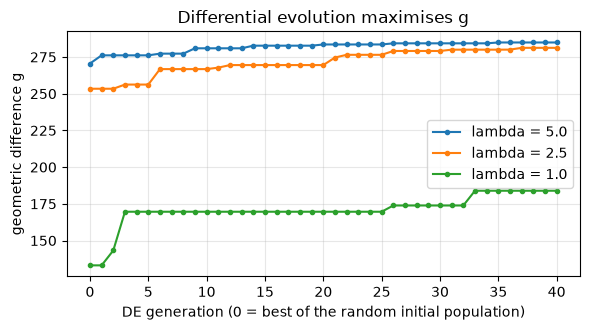

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for lam, r in runs.items():
    ax.plot(r["history"], marker="o", ms=3, label=f"lambda = {lam}")
ax.set_xlabel("DE generation (0 = best of the random initial population)")
ax.set_ylabel("geometric difference g")
ax.set_title("Differential evolution maximises g")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Labels from the quantum primitive

With the evolved waveform `X = (x, f(x))` we compute `G_C` and `G_Q`, the top eigenvector `v` of `M = sqrt(G_Q) G_C^-1 sqrt(G_Q)`, the continuous label vector `l = sqrt(G_Q) v`, then `label = l > median(l)` and finally flip 5% of the labels at random (paper Section 5). Class 0 is "normal" and class 1 is "FDI". The classes are balanced by construction (median split).

Note that the labels are a property of the *data generator*: the whole set is used to define them, exactly as in the paper. The machine-learning models later never see this procedure, only the points and the labels, and are scored on held-out folds.

In [7]:
def make_labels(P, seed_offset):
    X = np.c_[P["x"], P["wave"](P["theta"])]
    F = quantum_features(X)
    GC, GQ = gram_classical(X), gram_quantum(F)
    S, M = geometric_matrix(GC, GQ)
    evals, evecs = np.linalg.eigh(M)
    l = S @ evecs[:, -1]
    y_clean = (l > np.median(l)).astype(int)
    rng = np.random.default_rng(SEED + 100 + seed_offset)
    flip = rng.choice(len(y_clean), int(round(LABEL_NOISE * len(y_clean))), replace=False)
    y = y_clean.copy(); y[flip] = 1 - y[flip]
    return X, F, y, y_clean, float(np.sqrt(evals[-1]))

for i, lam in enumerate(LAMBDAS):
    X, F, y, y_clean, g = make_labels(runs[lam], i)
    runs[lam].update(X=X, F=F, y=y, y_clean=y_clean, g_check=g)
    print(f"lambda={lam:>3}: n={len(y)}, g recomputed exactly={g:.1f} (DE reported {runs[lam]['g_best']:.1f}), class counts (0 normal / 1 FDI)={np.bincount(y).tolist()}, "
          f"flipped labels={int((y != y_clean).sum())}")

lambda=5.0: n=1000, g recomputed exactly=284.9 (DE reported 284.9), class counts (0 normal / 1 FDI)=[482, 518], flipped labels=50


lambda=2.5: n=1000, g recomputed exactly=281.2 (DE reported 281.2), class counts (0 normal / 1 FDI)=[506, 494], flipped labels=50


lambda=1.0: n=1000, g recomputed exactly=183.9 (DE reported 183.9), class counts (0 normal / 1 FDI)=[492, 508], flipped labels=50


## Dataset Exploration and Visualisation

The "dataset" of this paper is generated, not downloaded: three waveforms (one per wavelength `lambda`), each with `N_POINTS` labelled samples. Every point shown below is a real generated observation `(x_i, y_i)` with its ground-truth label (0 = normal, 1 = FDI). Nothing is invented for the plots. The paper has only binary classes, so there are no attack families to colour by.

### Shape, feature names, labels and class counts

In [8]:
for lam in LAMBDAS:
    r = runs[lam]
    print(f"--- lambda = {lam} (m = {r['m']} harmonics) ---")
    print("  classical input  X:", r["X"].shape, "features: ['x', 'y']")
    print("  quantum features F:", r["F"].shape, "features:", FEATURE_NAMES)
    print("  original label values:", sorted(set(r["y"].tolist())), "class counts:", dict(zip(*np.unique(r["y"], return_counts=True))))
    print(f"  x range [{r['X'][:, 0].min():.1f}, {r['X'][:, 0].max():.1f}], y range [{r['X'][:, 1].min():.3f}, {r['X'][:, 1].max():.3f}]")
df_head = pd.DataFrame(np.c_[runs[LAMBDAS[-1]]["X"], runs[LAMBDAS[-1]]["y"]][:6], columns=["x", "y", "label"])
df_head

--- lambda = 5.0 (m = 4 harmonics) ---
  classical input  X: (1000, 2) features: ['x', 'y']
  quantum features F: (1000, 12) features: ['q0_X', 'q0_Y', 'q0_Z', 'q1_X', 'q1_Y', 'q1_Z', 'q2_X', 'q2_Y', 'q2_Z', 'q3_X', 'q3_Y', 'q3_Z']
  original label values: [0, 1] class counts: {np.int64(0): np.int64(482), np.int64(1): np.int64(518)}
  x range [-10.0, 10.0], y range [-0.114, 0.137]
--- lambda = 2.5 (m = 8 harmonics) ---
  classical input  X: (1000, 2) features: ['x', 'y']
  quantum features F: (1000, 12) features: ['q0_X', 'q0_Y', 'q0_Z', 'q1_X', 'q1_Y', 'q1_Z', 'q2_X', 'q2_Y', 'q2_Z', 'q3_X', 'q3_Y', 'q3_Z']
  original label values: [0, 1] class counts: {np.int64(0): np.int64(506), np.int64(1): np.int64(494)}
  x range [-10.0, 10.0], y range [-0.177, 0.143]
--- lambda = 1.0 (m = 20 harmonics) ---
  classical input  X: (1000, 2) features: ['x', 'y']
  quantum features F: (1000, 12) features: ['q0_X', 'q0_Y', 'q0_Z', 'q1_X', 'q1_Y', 'q1_Z', 'q2_X', 'q2_Y', 'q2_Z', 'q3_X', 'q3_Y', 'q3_Z']

,x,y,label
0,-10.00000,-0.311526,0.0
1,-9.97998,-0.273205,0.0
2,-9.95996,-0.273818,0.0
3,-9.93994,-0.257632,0.0
4,-9.91992,-0.278906,0.0
5,-9.89990,-0.234900,0.0


### Class distribution

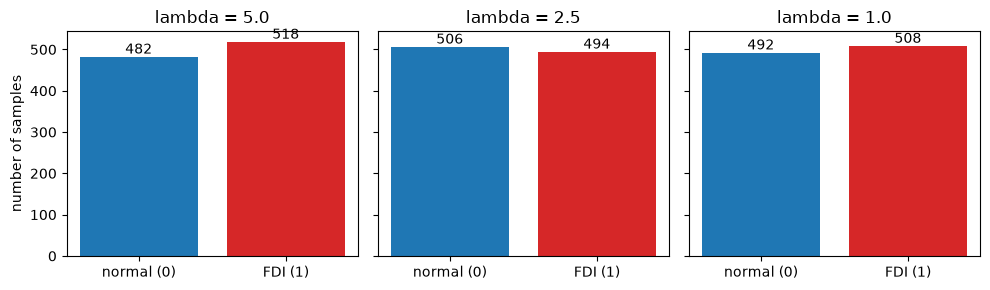

In [9]:
fig, axes = plt.subplots(1, len(LAMBDAS), figsize=(10, 3), sharey=True)
for ax, lam in zip(axes, LAMBDAS):
    counts = np.bincount(runs[lam]["y"], minlength=2)
    ax.bar(["normal (0)", "FDI (1)"], counts, color=["#1f77b4", "#d62728"])
    for i, c in enumerate(counts):
        ax.text(i, c, str(c), ha="center", va="bottom")
    ax.set_title(f"lambda = {lam}")
axes[0].set_ylabel("number of samples")
plt.tight_layout(); plt.show()

### Real observations coloured by their ground-truth label

For every wavelength, from left to right: (1) the evolved waveform with its labels (the paper's Figures 4 to 6); (2) the raw PCA coordinates of the classical input `(x, y)`, with scaler and PCA fitted on the **training split** only; (3) the same coordinates scaled to `[0, pi]` (the angle range used by angle-encoding models; test angles clipped); (4) PCA of the 12 quantum features. The labels look random in the classical views and separate in the quantum view, which is the whole point of the construction.

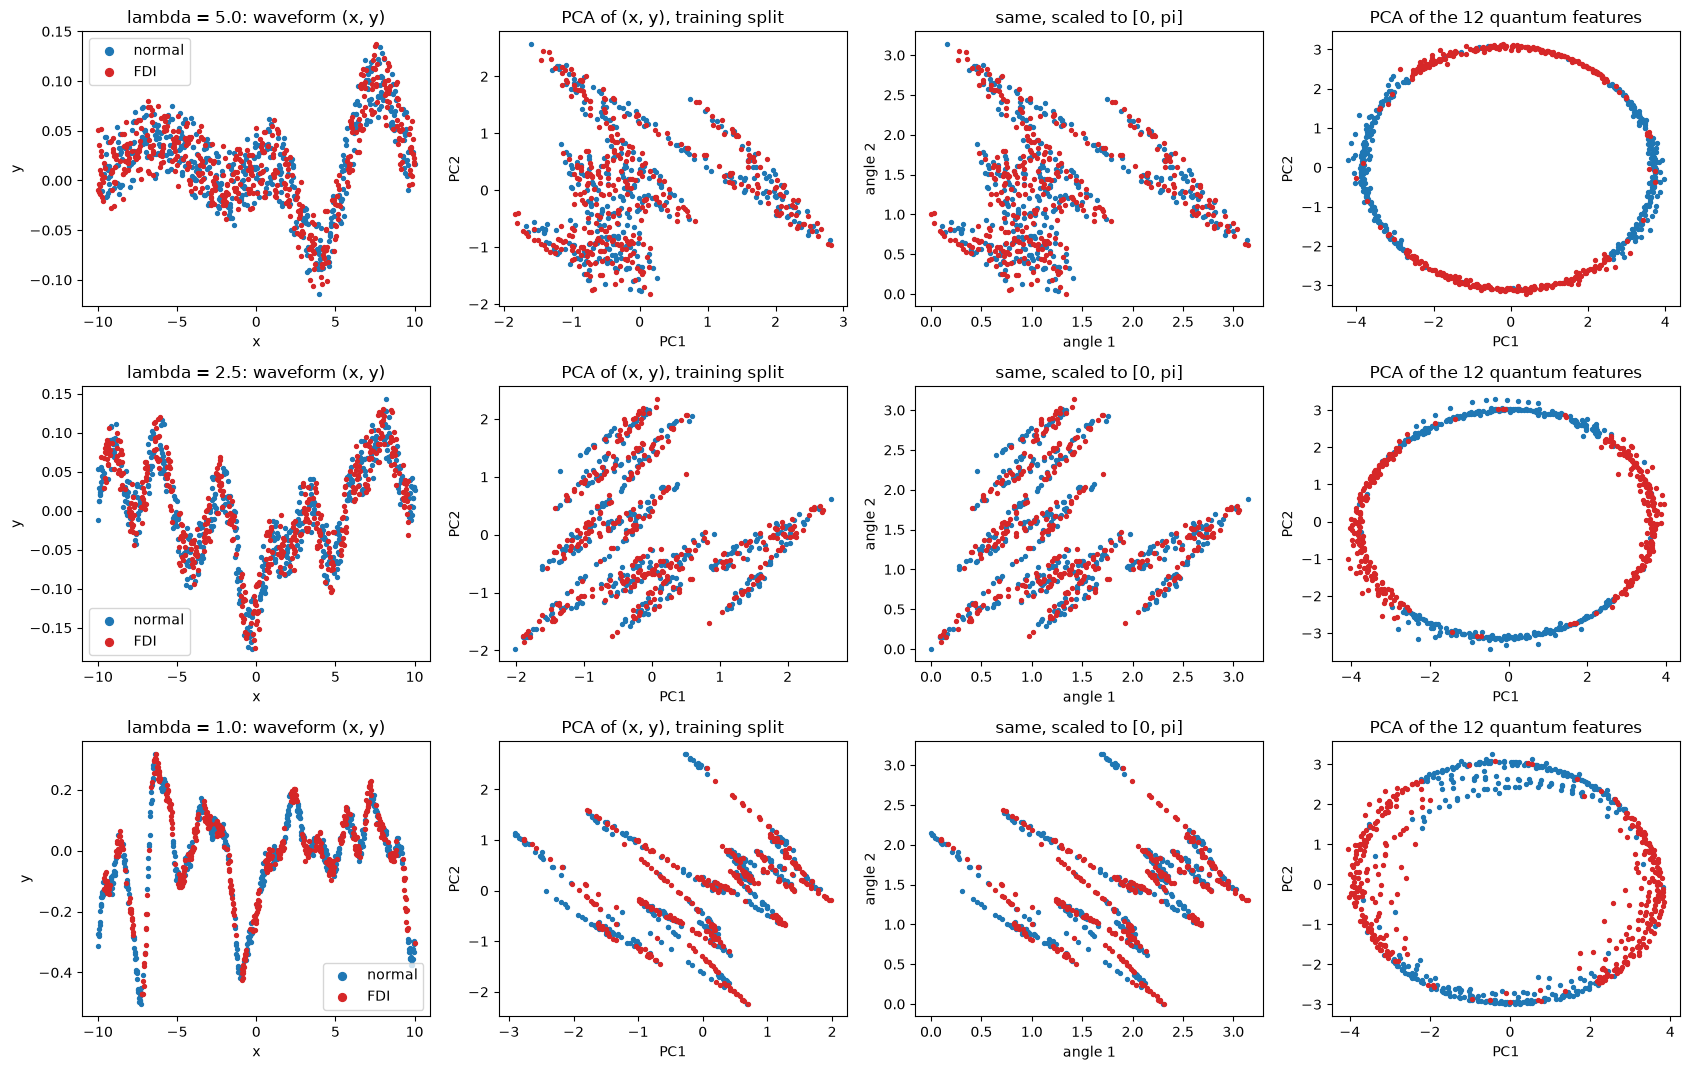

In [10]:
COL = {0: "#1f77b4", 1: "#d62728"}
fig, axes = plt.subplots(len(LAMBDAS), 4, figsize=(17, 3.6 * len(LAMBDAS)))
for row, lam in zip(axes, LAMBDAS):
    r = runs[lam]; X, F, y = r["X"], r["F"], r["y"]
    idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.3, stratify=y, random_state=SEED)
    # (1) the waveform with labels
    for c, name in [(0, "normal"), (1, "FDI")]:
        row[0].scatter(X[y == c, 0], X[y == c, 1], s=8, c=COL[c], label=name)
    row[0].set_title(f"lambda = {lam}: waveform (x, y)"); row[0].set_xlabel("x"); row[0].set_ylabel("y"); row[0].legend(markerscale=2)
    # (2) PCA of the classical input, fitted on training split
    sc = StandardScaler().fit(X[idx_tr]); pca = PCA(2, random_state=SEED).fit(sc.transform(X[idx_tr]))
    Ztr, Zte = pca.transform(sc.transform(X[idx_tr])), pca.transform(sc.transform(X[idx_te]))
    for c in (0, 1):
        row[1].scatter(Ztr[y[idx_tr] == c, 0], Ztr[y[idx_tr] == c, 1], s=8, c=COL[c])
    row[1].set_title("PCA of (x, y), training split"); row[1].set_xlabel("PC1"); row[1].set_ylabel("PC2")
    # (3) same coordinates scaled to [0, pi]
    mm = MinMaxScaler((0, np.pi)).fit(Ztr); A = mm.transform(Ztr); Ate = np.clip(mm.transform(Zte), 0, np.pi)
    for c in (0, 1):
        row[2].scatter(A[y[idx_tr] == c, 0], A[y[idx_tr] == c, 1], s=8, c=COL[c])
    row[2].set_title("same, scaled to [0, pi]"); row[2].set_xlabel("angle 1"); row[2].set_ylabel("angle 2")
    # (4) PCA of the 12 quantum features
    scq = StandardScaler().fit(F[idx_tr]); pq = PCA(2, random_state=SEED).fit(scq.transform(F[idx_tr]))
    Q = pq.transform(scq.transform(F[idx_tr]))
    for c in (0, 1):
        row[3].scatter(Q[y[idx_tr] == c, 0], Q[y[idx_tr] == c, 1], s=8, c=COL[c])
    row[3].set_title("PCA of the 12 quantum features"); row[3].set_xlabel("PC1"); row[3].set_ylabel("PC2")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The quantum model of the paper is a *feature map*: a fixed circuit with no trainable parameters, whose single-qubit reduced density matrices become the inputs of the neural network. The circuit below is the one the feature map actually runs, written as a Qiskit `QuantumCircuit` with the two data inputs `x`, `y` as symbolic parameters:

* a wall of fixed random U3 gates (`U_1qb`);
* `n_trotter = 10` Trotter steps, each with three Heisenberg bonds (qubits 0-1, 1-2, 2-3) made of `RXX`, `RYY`, `RZZ` gates, `exp(-i t (XX+YY+ZZ)) = RXX(2t) RYY(2t) RZZ(2t)` because the three terms commute;
* the "measurement" is the exact single-qubit reduced density matrix (Bloch vector) of every qubit, read from the statevector (no shot noise).

**Assumptions where the paper omits details.** Number of qubits (4), which input drives which bond (`x` on even bonds, `y` on the odd bond), the random rotation angles (seeded U3 gates) and exact-statevector evaluation are choices of this notebook (see the table in Section 1).

### The executed circuit

qubits: 4 | depth: 91 | gates: {'rxx': 30, 'ryy': 30, 'rzz': 30, 'barrier': 11, 'u': 4}
data-input parameters: 2 | trainable parameters: 0 (fixed random rotations: 12 angles)


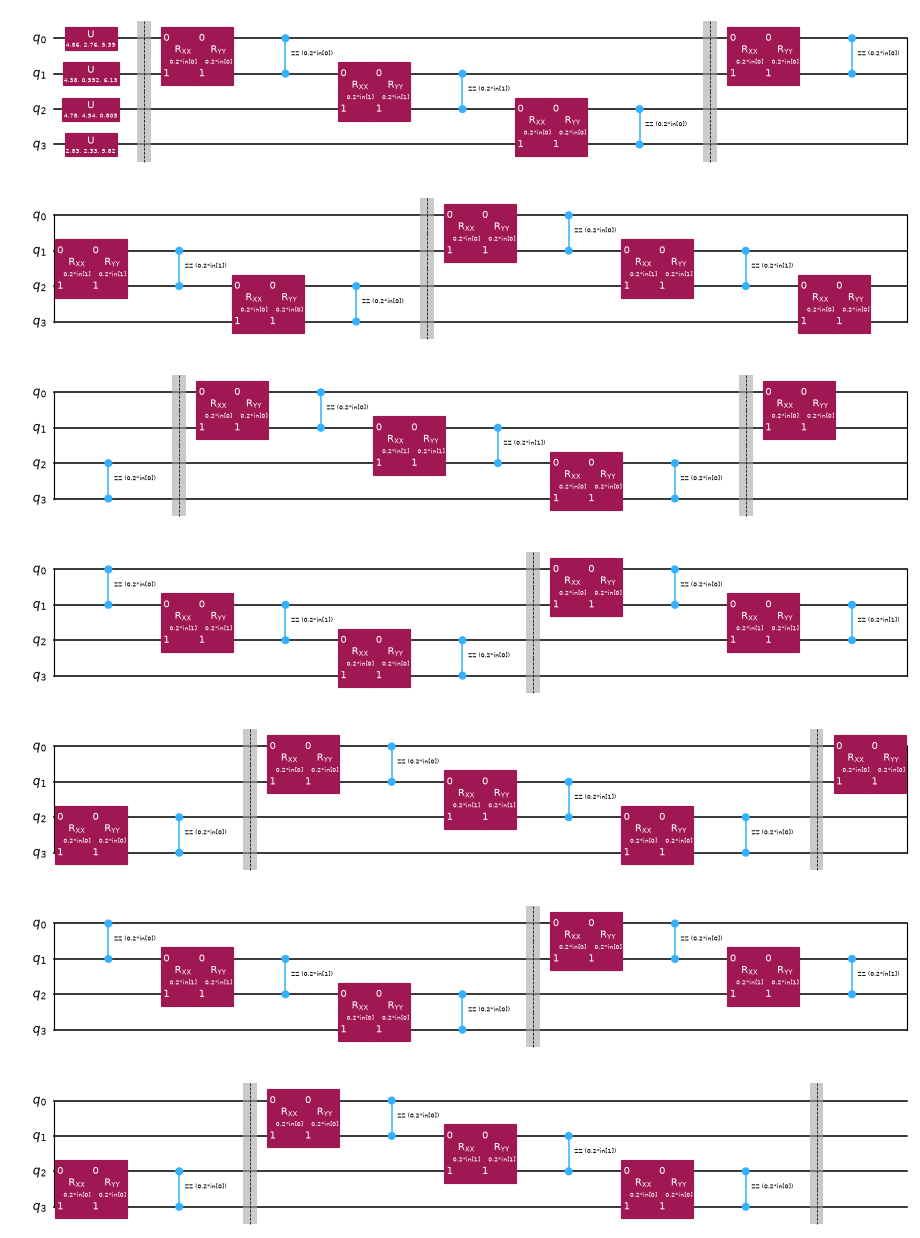

In [11]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, Pauli

def feature_map_circuit():
    p = ParameterVector("in", 2)                        # p[0] = x, p[1] = y
    qc = QuantumCircuit(N_QUBITS, name="V(X/n)^n U1qb")
    for q in range(N_QUBITS):
        qc.u(*[float(a) for a in ANGLES[q]], q)         # random single-qubit wall U_1qb
    qc.barrier()
    for step in range(N_TROTTER):
        for k in range(N_QUBITS - 1):
            t = p[k % 2] / N_TROTTER
            qc.rxx(2 * t, k, k + 1); qc.ryy(2 * t, k, k + 1); qc.rzz(2 * t, k, k + 1)
        qc.barrier()
    return qc, p

qc, params = feature_map_circuit()
print("qubits:", qc.num_qubits, "| depth:", qc.depth(), "| gates:", dict(qc.count_ops()))
print("data-input parameters:", qc.num_parameters, "| trainable parameters: 0 (fixed random rotations: 12 angles)")
qc.draw("mpl", fold=24, scale=0.55)

### Equivalence check: Qiskit circuit versus the NumPy simulator used for the experiments

The experiments call `quantum_features`, which uses the closed-form Heisenberg gate. Here we bind real data points to the Qiskit circuit, take the exact statevector, compute `<X>, <Y>, <Z>` of every qubit with Qiskit's Pauli operators and require agreement to 1e-9.

In [12]:
pts = runs[LAMBDAS[-1]]["X"][::max(1, N_POINTS // 6)][:6]
F_np = quantum_features(pts)
F_qk = []
for xy in pts:
    sv = Statevector(qc.assign_parameters({params[0]: xy[0], params[1]: xy[1]}))
    row = []
    for q in range(N_QUBITS):
        for P_ in "XYZ":
            label = ["I"] * N_QUBITS; label[N_QUBITS - 1 - q] = P_      # Qiskit labels are little-endian
            row.append(sv.expectation_value(Pauli("".join(label))).real)
    F_qk.append(row)
F_qk = np.array(F_qk)
print("max |numpy - qiskit| over", F_np.size, "feature values:", float(np.abs(F_np - F_qk).max()))
assert np.allclose(F_np, F_qk, atol=1e-9), "NumPy simulator and Qiskit circuit disagree"
print("EQUIVALENCE OK: the circuit drawn above gives the same features as the simulator used in the experiments")

max |numpy - qiskit| over 72 feature values: 4.551914400963142e-15
EQUIVALENCE OK: the circuit drawn above gives the same features as the simulator used in the experiments


## 7. The two learners and the baselines

* **Classical NN**: standardised `(x, y)` -> `(128, 64, 32, 16)` ReLU -> sigmoid, log-loss (binary cross-entropy), Adam, `EPOCHS` epochs.
* **Quantum NN**: identical network, standardised 12 quantum features.
* Extra baselines (not in the paper): random forest and RBF-SVM on both inputs, so you can see how much of the gap is due to the network and how much to the input representation.

Scalers are fitted inside every training fold only. Metrics treat FDI (label 1) as the positive class. Mean, standard deviation (STD) and median absolute deviation (MAD) are computed over the 10 folds, the same triple the paper reports.

In [13]:
def make_models():
    return {
        "NN": lambda: make_pipeline(StandardScaler(), MLPClassifier(
            hidden_layer_sizes=HIDDEN, activation="relu", solver="adam", max_iter=EPOCHS, n_iter_no_change=EPOCHS + 1,
            batch_size=200, random_state=SEED)),    # CHOICE: sklearn MLP, mini-batch 200; n_iter_no_change disables early stopping
        "RandomForest": lambda: make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, random_state=SEED)),
        "SVC-rbf": lambda: make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")),
    }

def cross_validate_model(factory, Z, y):
    skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
    rows, pred_all = [], np.zeros_like(y)
    t0 = time.perf_counter()
    for tr, te in skf.split(Z, y):
        clf = factory().fit(Z[tr], y[tr])
        pr = clf.predict(Z[te]); pred_all[te] = pr
        rows.append([accuracy_score(y[te], pr), precision_score(y[te], pr, zero_division=0),
                     recall_score(y[te], pr, zero_division=0), f1_score(y[te], pr, zero_division=0)])
    return np.array(rows), pred_all, time.perf_counter() - t0

results = {}   # (lam, input, model) -> dict
for lam in LAMBDAS:
    r = runs[lam]
    for inp, Z in [("Classical", r["X"]), ("Quantum", r["F"])]:
        for mname, fac in make_models().items():
            folds, pred, secs = cross_validate_model(fac, Z, r["y"])
            results[(lam, inp, mname)] = dict(folds=folds, pred=pred, secs=secs)
        print(f"lambda={lam:>3} {inp:9s}: " + ", ".join(
            f"{m} acc={results[(lam, inp, m)]['folds'][:, 0].mean():.3f}" for m in ["NN", "RandomForest", "SVC-rbf"]))

lambda=5.0 Classical: NN acc=0.469, RandomForest acc=0.751, SVC-rbf acc=0.472


lambda=5.0 Quantum  : NN acc=0.935, RandomForest acc=0.940, SVC-rbf acc=0.930


lambda=2.5 Classical: NN acc=0.474, RandomForest acc=0.794, SVC-rbf acc=0.463


lambda=2.5 Quantum  : NN acc=0.932, RandomForest acc=0.939, SVC-rbf acc=0.934


lambda=1.0 Classical: NN acc=0.686, RandomForest acc=0.862, SVC-rbf acc=0.562


lambda=1.0 Quantum  : NN acc=0.921, RandomForest acc=0.935, SVC-rbf acc=0.939


## 8. The paper's Tables 2 to 4, re-drawn

For every wavelength: mean (STD; MAD) of accuracy, precision, recall and F1 over the 10 folds for the NN on classical and on quantum inputs.

In [14]:
def fmt(a):
    return f"{a.mean():.3f} ({a.std():.3f}; {median_abs_deviation(a):.3f})"

tables = {}
for lam in LAMBDAS:
    rows = []
    for inp in ["Classical", "Quantum"]:
        f = results[(lam, inp, "NN")]["folds"]
        rows.append([inp] + [fmt(f[:, j]) for j in range(4)])
    tables[lam] = pd.DataFrame(rows, columns=["Algorithm", "Accuracy", "Precision", "Recall", "F1 score"]).set_index("Algorithm")
    print(f"Table (this notebook), lambda = {lam}: 10-fold CV, mean (STD; MAD)")
    display(tables[lam]); print()

Table (this notebook), lambda = 5.0: 10-fold CV, mean (STD; MAD)


,Accuracy,Precision,Recall,F1 score
Algorithm,,,,
Classical,0.469 (0.045; 0.025),0.488 (0.035; 0.019),0.585 (0.085; 0.033),0.531 (0.053; 0.023)
Quantum,0.935 (0.020; 0.010),0.951 (0.030; 0.019),0.923 (0.029; 0.020),0.936 (0.019; 0.011)



Table (this notebook), lambda = 2.5: 10-fold CV, mean (STD; MAD)


,Accuracy,Precision,Recall,F1 score
Algorithm,,,,
Classical,0.474 (0.048; 0.045),0.465 (0.054; 0.055),0.457 (0.087; 0.045),0.459 (0.068; 0.049)
Quantum,0.932 (0.033; 0.025),0.925 (0.038; 0.027),0.939 (0.037; 0.031),0.932 (0.033; 0.027)


Table (this notebook), lambda = 1.0: 10-fold CV, mean (STD; MAD)


,Accuracy,Precision,Recall,F1 score
Algorithm,,,,
Classical,0.686 (0.043; 0.035),0.699 (0.053; 0.036),0.681 (0.065; 0.069),0.687 (0.042; 0.016)
Quantum,0.921 (0.027; 0.030),0.928 (0.051; 0.040),0.919 (0.022; 0.010),0.923 (0.025; 0.025)


### Extra baselines and timing

In [15]:
rows = []
for lam in LAMBDAS:
    for inp in ["Classical", "Quantum"]:
        row = {"lambda": lam, "input": inp}
        for m in ["NN", "RandomForest", "SVC-rbf"]:
            row[f"{m} acc"] = round(results[(lam, inp, m)]["folds"][:, 0].mean(), 3)
        row["NN train+predict (s, 10 folds)"] = round(results[(lam, inp, "NN")]["secs"], 1)
        rows.append(row)
baselines = pd.DataFrame(rows)
baselines

,lambda,input,NN acc,RandomForest acc,SVC-rbf acc,"NN train+predict (s, 10 folds)"
0,5.0,Classical,0.469,0.751,0.472,156.9
1,5.0,Quantum,0.935,0.940,0.930,140.2
2,2.5,Classical,0.474,0.794,0.463,122.2
3,2.5,Quantum,0.932,0.939,0.934,124.8
4,1.0,Classical,0.686,0.862,0.562,126.6
5,1.0,Quantum,0.921,0.935,0.939,130.3


### Accuracy against wavelength, and confusion matrices (FDI = positive class)

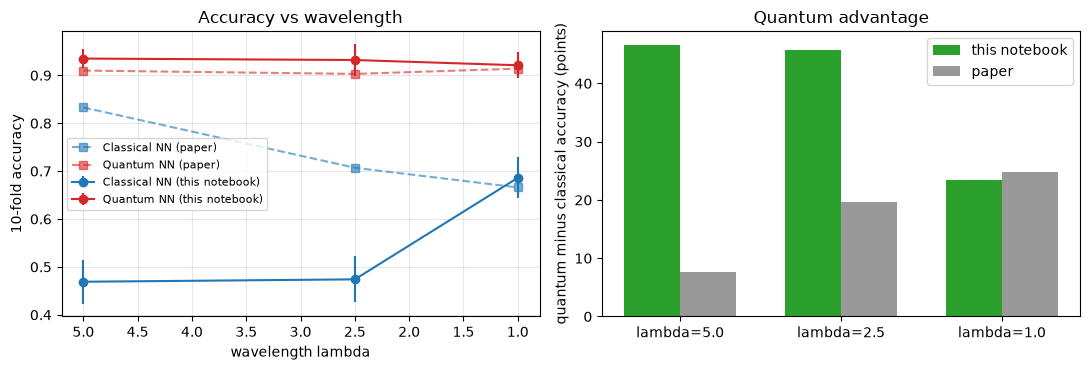

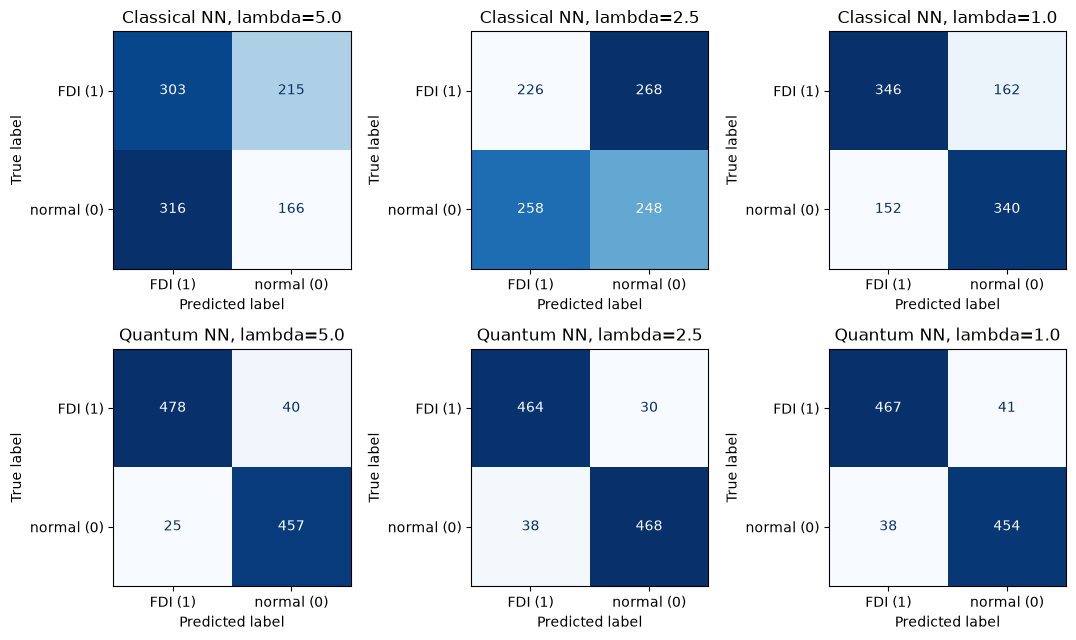

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for inp, col in [("Classical", "#1f77b4"), ("Quantum", "#d62728")]:
    mine = [results[(lam, inp, "NN")]["folds"][:, 0].mean() for lam in LAMBDAS]
    err = [results[(lam, inp, "NN")]["folds"][:, 0].std() for lam in LAMBDAS]
    paper = [PAPER[lam][inp][0] for lam in LAMBDAS]
    axes[0].errorbar(LAMBDAS, mine, yerr=err, marker="o", color=col, label=f"{inp} NN (this notebook)")
    axes[0].plot(LAMBDAS, paper, marker="s", ls="--", color=col, alpha=.6, label=f"{inp} NN (paper)")
axes[0].set_xlabel("wavelength lambda"); axes[0].set_ylabel("10-fold accuracy"); axes[0].invert_xaxis()
axes[0].set_title("Accuracy vs wavelength"); axes[0].legend(fontsize=8); axes[0].grid(alpha=.3)
gaps = [results[(lam, "Quantum", "NN")]["folds"][:, 0].mean() - results[(lam, "Classical", "NN")]["folds"][:, 0].mean() for lam in LAMBDAS]
pgap = [PAPER[lam]["Quantum"][0] - PAPER[lam]["Classical"][0] for lam in LAMBDAS]
w = 0.35; xs = np.arange(len(LAMBDAS))
axes[1].bar(xs - w / 2, np.array(gaps) * 100, w, label="this notebook", color="#2ca02c")
axes[1].bar(xs + w / 2, np.array(pgap) * 100, w, label="paper", color="#999999")
axes[1].set_xticks(xs); axes[1].set_xticklabels([f"lambda={l}" for l in LAMBDAS])
axes[1].set_ylabel("quantum minus classical accuracy (points)"); axes[1].set_title("Quantum advantage"); axes[1].legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, len(LAMBDAS), figsize=(11, 6.5))
for j, lam in enumerate(LAMBDAS):
    for i, inp in enumerate(["Classical", "Quantum"]):
        cm = confusion_matrix(runs[lam]["y"], results[(lam, inp, "NN")]["pred"], labels=[1, 0])
        ConfusionMatrixDisplay(cm, display_labels=["FDI (1)", "normal (0)"]).plot(ax=axes[i, j], colorbar=False, cmap="Blues")
        axes[i, j].set_title(f"{inp} NN, lambda={lam}")
plt.tight_layout(); plt.show()

## 9. The evolved waveforms, labelled by the quantum primitive (the paper's Figures 4 to 6)

Same plot as in the Dataset section, now with the learned decision visible: points the quantum-feature network misclassified are circled. The waveforms are small-amplitude oscillations plus noise; to a classical eye the colouring looks random.

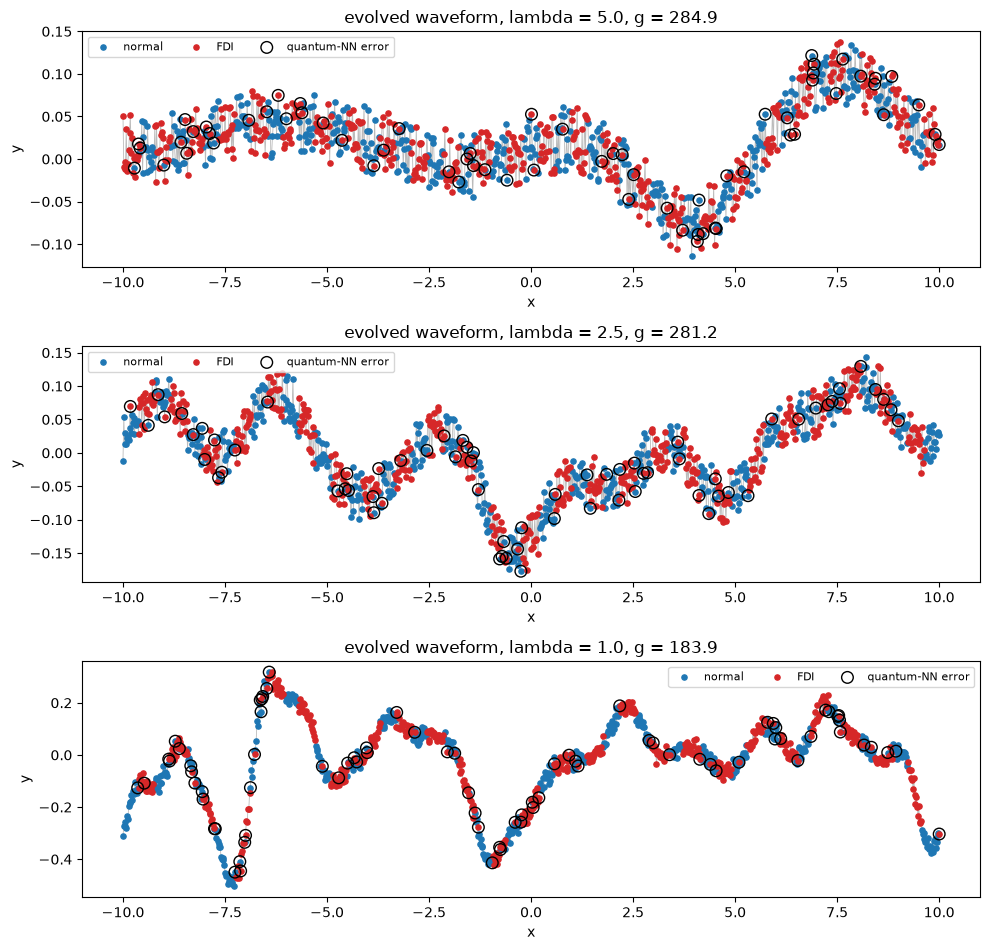

In [17]:
fig, axes = plt.subplots(len(LAMBDAS), 1, figsize=(10, 3.2 * len(LAMBDAS)))
for ax, lam in zip(axes, LAMBDAS):
    r = runs[lam]; X, y = r["X"], r["y"]
    ax.plot(X[:, 0], X[:, 1], color="#bbbbbb", lw=.6, zorder=1)
    for c, name in [(0, "normal"), (1, "FDI")]:
        ax.scatter(X[y == c, 0], X[y == c, 1], s=14, c=COL[c], label=name, zorder=2)
    wrong = results[(lam, "Quantum", "NN")]["pred"] != y
    ax.scatter(X[wrong, 0], X[wrong, 1], s=70, facecolors="none", edgecolors="k", label="quantum-NN error", zorder=3)
    ax.set_title(f"evolved waveform, lambda = {lam}, g = {r['g_best']:.1f}"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

## 10. Side-by-side with the paper

A claim counts as **reproduced** when the notebook value is within 0.02 of the paper's (accuracy, precision, recall, F1); otherwise **not reached** (below the paper by the stated gap) or **exceeded** (above it). Because this notebook uses a much smaller dataset and DE budget, deviations are expected and are reported rather than hidden.

In [18]:
def verdict(mine, paper, tol=0.02):
    d = mine - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

rows = []
for lam in LAMBDAS:
    for inp in ["Classical", "Quantum"]:
        f = results[(lam, inp, "NN")]["folds"]
        for j, name in enumerate(["accuracy", "precision", "recall", "F1"]):
            mine, pap = f[:, j].mean(), PAPER[lam][inp][j]
            rows.append([lam, inp, name, pap, round(mine, 3), round(mine - pap, 3), verdict(mine, pap)])
cmp_df = pd.DataFrame(rows, columns=["lambda", "model", "metric", "paper", "notebook", "gap", "verdict"])
display(cmp_df)
print(cmp_df.groupby("verdict").size().to_string())

,lambda,model,metric,paper,notebook,gap,verdict
0,5.0,Classical,accuracy,0.833,0.469,-0.364,not reached
1,5.0,Classical,precision,0.868,0.488,-0.380,not reached
2,5.0,Classical,recall,0.796,0.585,-0.211,not reached
3,5.0,Classical,F1,0.829,0.531,-0.298,not reached
4,5.0,Quantum,accuracy,0.910,0.935,0.025,exceeded
5,5.0,Quantum,precision,0.914,0.951,0.037,exceeded
6,5.0,Quantum,recall,0.912,0.923,0.011,reproduced
7,5.0,Quantum,F1,0.912,0.936,0.024,exceeded
8,2.5,Classical,accuracy,0.707,0.474,-0.233,not reached
9,2.5,Classical,precision,0.734,0.465,-0.269,not reached


verdict
exceeded       9
not reached    8
reproduced     7


In [19]:
acc = lambda lam, inp: results[(lam, inp, "NN")]["folds"][:, 0].mean()
cq = [acc(l, "Quantum") for l in LAMBDAS]; cc = [acc(l, "Classical") for l in LAMBDAS]
gap = [q - c for q, c in zip(cq, cc)]
claims = [
    ("Quantum NN beats classical NN at every wavelength", all(g > 0 for g in gap), f"gaps = {[round(g * 100, 1) for g in gap]} points"),
    ("Gap at lambda=5 is about 7 points (paper 7.7)", abs(gap[0] - 0.077) <= 0.02, f"{gap[0] * 100:.1f} points"),
    ("Gap at lambda=1 exceeds 25 points (paper 24.8)", gap[-1] >= 0.25, f"{gap[-1] * 100:.1f} points"),
    ("Classical accuracy falls as the wavelength shrinks", cc[0] > cc[1] > cc[2], f"{[round(c, 3) for c in cc]}"),
    ("Quantum accuracy stays stable (about 0.90 to 0.91) across wavelengths", max(cq) - min(cq) <= 0.03 and min(cq) >= 0.88, f"{[round(c, 3) for c in cq]}"),
]
print("Claim-level verdicts")
for name, ok, ev in claims:
    print(f"  [{'reproduced' if ok else 'not reached'}] {name}: {ev}")
print("\nClaims the notebook cannot check: the 6-hour DE budgets, the exact 1000-point waveforms, the paper's hidden qubit count and kernel widths,")
print("and any real smart-grid behaviour (no real FDI data or quantum sensor data exists in the paper).")

Claim-level verdicts
  [reproduced] Quantum NN beats classical NN at every wavelength: gaps = [np.float64(46.6), np.float64(45.8), np.float64(23.5)] points
  [not reached] Gap at lambda=5 is about 7 points (paper 7.7): 46.6 points
  [not reached] Gap at lambda=1 exceeds 25 points (paper 24.8): 23.5 points
  [not reached] Classical accuracy falls as the wavelength shrinks: [np.float64(0.469), np.float64(0.474), np.float64(0.686)]
  [reproduced] Quantum accuracy stays stable (about 0.90 to 0.91) across wavelengths: [np.float64(0.935), np.float64(0.932), np.float64(0.921)]

Claims the notebook cannot check: the 6-hour DE budgets, the exact 1000-point waveforms, the paper's hidden qubit count and kernel widths,
and any real smart-grid behaviour (no real FDI data or quantum sensor data exists in the paper).


## 11. Reading the paper critically

1. **The advantage is built in.** The labels are produced by a rule that uses the *same* quantum feature map that the quantum learner receives as input. Compare the baseline table in Section 8: a random forest or an RBF-SVM that is given the 12 quantum features scores about the same as the quantum-input network, so what matters is the input representation, not the network. The comparison therefore shows that *information that was used to create the labels helps predict them*, not that a quantum computer learns something a classical computer cannot.
2. **Unequal inputs.** The classical network sees 2 numbers `(x, y)`, the quantum network sees 12. Giving the classical network a richer representation (Fourier features of `x`, for instance) would be a fairer control; this is Exercise 2.
3. **The quantum features are classically simulable here.** Four qubits and nearest-neighbour Heisenberg gates are trivial to simulate (this notebook does it in NumPy). The paper's argument for quantum data requires that the features come from a physical quantum device and that no efficient classical surrogate exists; neither is shown.
4. **No real grid data.** There is no recorded waveform and no real attack. The data statement says the data is confidential, but the experiment itself is fully synthetic and reproducible, as this notebook shows. The "FDI" label is a name for one half of a median split.
5. **Search budget matters.** The paper ran 6 hours of DE per wavelength on 1000 points; here only a few thousand fitness evaluations are used. Even so the geometric difference of random waveforms is already large, so most of the effect comes from the label rule, not from the evolution.
6. **Statistics.** Ten-fold CV on 1000 points of a single evolved waveform per wavelength, with a single seed, gives standard deviations of 2 to 7 points. Differences between wavelengths of a few points are within noise.
7. **Balanced data.** Real FDI detection is highly imbalanced; the paper acknowledges this and leaves it to future work.
8. **The classical score depends on unstated choices.** How fast the labels oscillate along `x` depends on the scale of the angles fed to the circuit and on the sampling density. In this notebook the labels oscillate quickly in `x`, so at lambda = 5 and 2.5 the classical network sits at chance (0.47; values below 0.5 occur when a flexible model memorises noise in the training folds), while the classical random forest, which can carve the `x` axis into intervals, does clearly better (0.75 to 0.86). Only at lambda = 1, where `y` carries more structure, does the classical network reach 0.69, close to the paper's 0.67. The paper reports a milder classical failure at lambda = 5 and 2.5 (0.83 and 0.71) and a falling trend with shrinking wavelength that we do not see, so its generator probably differs in the unstated angle scale or kernel widths. Exercise 6 lets you test this.

## 12. Exercises

1. Change `MAXITER` to 300 (with `FAST_MODE = False`). How do `g` and the accuracy gap change?
2. Give the classical network a fairer input: add `sin(2 pi j x / L)` and `cos(2 pi j x / L)` for `j = 1..5` to `(x, y)`. Does the gap shrink?
3. Change `GAMMA_Q` to 0.1 and 10. The labels are redefined each time. Which setting gives the largest `g` and the largest accuracy gap?
4. Replace the bond coefficients (`x` on even bonds, `y` on odd bonds) by a 6-qubit chain with `x, y, x, y, x`. Does the circuit in the architecture section still agree with the simulator?
5. Make the problem imbalanced: label only the top 10% of `l` as FDI. Report precision, recall and F1 of both networks instead of accuracy.
6. Multiply `x` by 0.1 before it enters `quantum_features` (and the Gram matrices) so that the labels oscillate more slowly. Does the classical accuracy move towards the paper's 0.67 to 0.83?